# **Step 4 of 7: DBSCAN Clustering (HR Employees)**

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) finds clusters as **dense regions**. It does not need k.
- `eps`: the radius of the neighbourhood around a point
- `min_samples`: how many points must be inside `eps` for a point to be a **core point**
- **Core point:** has at least `min_samples` neighbours. **Border point:** near a core point but not core itself. **Noise (-1):** neither. Clusters grow by connecting core points.

Good for: odd-shaped clusters, **outliers are labelled as noise** (e.g. unusual employees). Weak for: clusters with very different densities, high dimensions, sensitive to `eps`.

### 1. Import and load the preprocessed data
This notebook uses the files made in **step 1 (01_HR_Data_Preprocessing)**:
- `hr_clean.csv`: cleaned data in original units (used to describe the clusters)
- `hr_preprocessed.csv`: scaled clustering features (used by the algorithm)
- `hr_scaler.pkl`, `preprocessing_info.json` (and `hr_truth.csv`, demo data only)

Keep these files in the same folder as this notebook.

> The data is **synthetic demo data** (about 4 hidden employee groups + 3% unusual employees). Because we know the hidden groups, the result can also be checked with *external* metrics. With real HR data this check is not possible and only the internal metrics are used.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_completeness_v_measure)
sns.set_theme(style='whitegrid')

# ---- files made by 01_HR_Data_Preprocessing.ipynb (keep them in the same folder) ----
need = ['hr_clean.csv', 'hr_preprocessed.csv', 'preprocessing_info.json', 'hr_scaler.pkl']
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f'Run 01_HR_Data_Preprocessing.ipynb first. Missing files: {missing}')

info = json.load(open('preprocessing_info.json'))
FEATURES, PROFILE_COLS = info['features'], info['profile_cols']

df = pd.read_csv('hr_clean.csv')                    # cleaned data, original units (used to describe the clusters)
X_df = pd.read_csv('hr_preprocessed.csv')           # scaled features (used by the algorithm)
assert (df['employee_id'].values == X_df['employee_id'].values).all(), 'files do not match'
X = X_df[FEATURES].values
scaler = joblib.load('hr_scaler.pkl')               # needed to prepare NEW employees

# hidden true groups: exist only in the synthetic demo data, used only to check the result at the end
if os.path.exists('hr_truth.csv'):
    df = df.merge(pd.read_csv('hr_truth.csv'), on='employee_id', how='left')
HAS_TRUTH = 'segment_true' in df.columns

print('Employees:', X.shape[0], '| clustering features:', FEATURES)
print('Hopkins statistic from step 1:', info['hopkins'], '| hidden truth available:', HAS_TRUTH)
df.head()

Employees: 1498 | clustering features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
Hopkins statistic from step 1: 0.747 | hidden truth available: True


,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,work_accident,promotion_last_5years,department,left,is_outlier_iqr,segment_true
0,1456,0.87,0.92,4.0,178.0,5.0,1,1,0,technical,0,0,Engaged high performers
1,1957,0.62,0.68,5.0,150.0,10.0,1,1,1,technical,0,0,Loyal long-tenure
2,1612,0.71,0.93,5.0,191.0,4.0,1,0,0,sales,1,0,Engaged high performers
3,1998,0.64,0.73,3.0,180.0,9.0,1,0,0,support,0,0,Loyal long-tenure
4,2037,0.35,0.51,2.0,169.0,2.0,2,0,0,sales,0,0,Disengaged underused


Helper functions used in all sections (metrics, plots, cluster profile):

In [2]:
def internal_metrics(X, labels):
    """Internal metrics (no true labels needed). Noise points (-1) are ignored."""
    labels = np.asarray(labels); mask = labels != -1
    n_clusters = len(set(labels[mask]))
    out = {'n_clusters': n_clusters, 'noise_%': round(100 * (~mask).mean(), 1),
           'silhouette': np.nan, 'calinski_harabasz': np.nan, 'davies_bouldin': np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        out['silhouette'] = silhouette_score(X[mask], labels[mask])
        out['calinski_harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
        out['davies_bouldin'] = davies_bouldin_score(X[mask], labels[mask])
    return out

def external_metrics(truth, labels):
    """External metrics: compare with the hidden true segments (demo data only)."""
    h, c, v = homogeneity_completeness_v_measure(truth, labels)
    return {'ARI': adjusted_rand_score(truth, labels), 'NMI': normalized_mutual_info_score(truth, labels),
            'homogeneity': h, 'completeness': c, 'v_measure': v}

def plot_clusters(Z, labels, ax, title, centers=None):
    """2D scatter of the clusters (Z = PCA coordinates). Noise = black x."""
    labels = np.asarray(labels); palette = sns.color_palette('tab10', 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(Z[m, 0], Z[m, 1], c='black', marker='x', s=25, label=f'Noise ({m.sum()})')
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7, color=palette[lab % 10], label=f'Cluster {lab} ({m.sum()})')
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Centers')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)

def cluster_profile(data, labels):
    """Average of every feature in each cluster (original units) + size."""
    labels = np.asarray(labels)
    prof = data[PROFILE_COLS].assign(cluster=labels).groupby('cluster').mean()
    prof['size'] = pd.Series(labels).value_counts().sort_index()
    prof['share_%'] = (100 * prof['size'] / len(labels)).round(1)
    return prof

def plot_profile(prof, title='Cluster profile (colour = high / low compared with other clusters, number = real average)'):
    feat = prof[PROFILE_COLS]
    z = (feat - feat.mean()) / (feat.std(ddof=0) + 1e-9)
    plt.figure(figsize=(9, 0.9 * len(prof) + 2))
    sns.heatmap(z, annot=feat.round(2), fmt='g', cmap='RdYlGn', center=0, cbar_kws={'label': 'relative level'})
    plt.title(title); plt.ylabel('Cluster'); plt.tight_layout(); plt.show()

### 2. Look at the data

In [3]:
df[PROFILE_COLS].describe().round(2)

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level
count,1498.00,1498.00,1498.00,1498.00,1498.00,1498.00
mean,0.55,0.73,4.12,196.67,4.76,0.93
std,0.23,0.16,1.45,47.51,2.24,0.74
min,0.09,0.36,2.00,96.00,2.00,0.00
25%,0.35,0.60,3.00,160.00,3.00,0.00
50%,0.57,0.77,4.00,191.00,4.00,1.00
75%,0.76,0.86,5.00,222.00,6.00,1.00
max,1.00,1.00,7.00,310.00,10.00,2.00


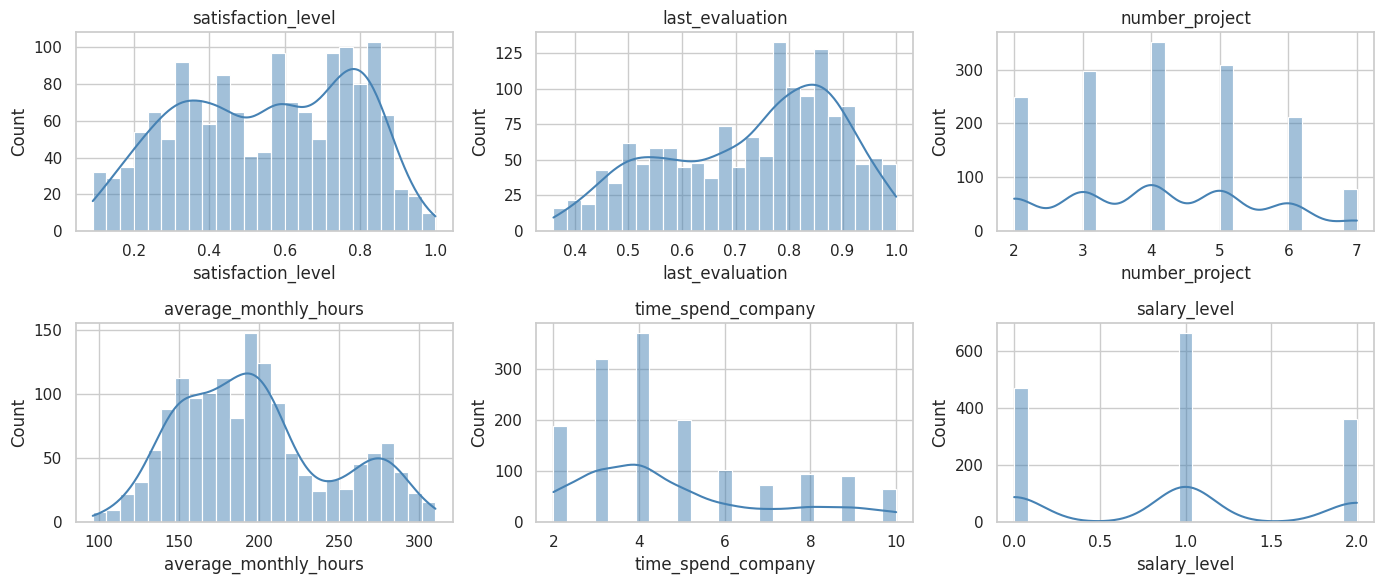

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, f in zip(ax.ravel(), PROFILE_COLS):
    sns.histplot(df[f], bins=25, kde=True, ax=a, color='steelblue')
    a.set_title(f)
plt.tight_layout(); plt.show()

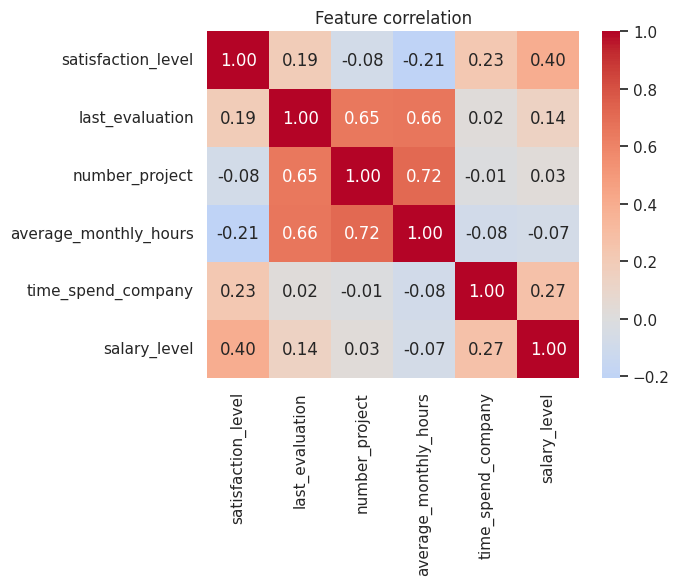

In [5]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[PROFILE_COLS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlation'); plt.show()

### 3. 2D view for plotting (PCA)
The data is already **cleaned and scaled in step 1**, so no preprocessing is needed here. PCA is used **only to draw** the clusters in 2D (the clustering itself uses all features).

In [6]:
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
print('Variance explained by the 2 plotted components:', (pca.explained_variance_ratio_.sum() * 100).round(1), '%')

Variance explained by the 2 plotted components: 72.9 %


### 4. Choose `eps` with the k-distance plot
For every employee we find the distance to its `min_samples`-th nearest neighbour and sort these distances. Most points are in dense areas (small distances); the curve bends sharply upwards where the **noise / sparse points** start. The **knee** of the curve is a good `eps`.
Rule of thumb for `min_samples`: **2 x number of features** (= 10 here).

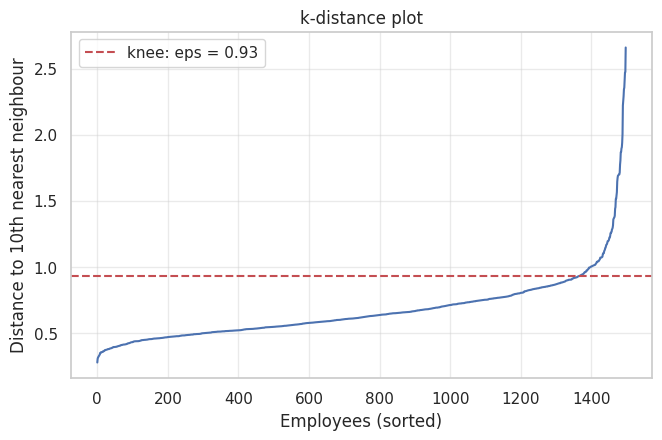

Suggested eps from the knee: 0.935


In [7]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

min_samples0 = 2 * len(FEATURES)
kdist = np.sort(NearestNeighbors(n_neighbors=min_samples0).fit(X).kneighbors(X)[0][:, -1])

# knee = point furthest from the straight line between the first and last point
n_ = len(kdist); x_ = np.arange(n_)
d = np.abs((kdist[-1] - kdist[0]) * x_ - (n_ - 1) * (kdist - kdist[0])) / np.hypot(kdist[-1] - kdist[0], n_ - 1)
eps_knee = kdist[d.argmax()]

plt.figure(figsize=(7.5, 4.5))
plt.plot(kdist); plt.axhline(eps_knee, color='r', ls='--', label=f'knee: eps = {eps_knee:.2f}')
plt.xlabel('Employees (sorted)'); plt.ylabel(f'Distance to {min_samples0}th nearest neighbour')
plt.title('k-distance plot'); plt.legend(); plt.grid(alpha=0.4); plt.show()
print('Suggested eps from the knee:', round(eps_knee, 3))

### 5. Tune `eps` and `min_samples` (grid search)
There are no true labels, so every combination is judged with **internal metrics** (silhouette, Calinski-Harabasz, Davies-Bouldin) plus the number of clusters and the % of noise.

In [8]:
# Selection rule: 2 to 8 clusters, at most 20% noise, then the best silhouette.
# (Silhouette alone would prefer 'a tiny dense cluster + almost everything else noise', so the rule keeps the result useful.)
# If nothing fits, the rule is relaxed step by step.
def pick_best(res, max_noise=20, min_c=2, max_c=8):
    res = res.dropna(subset=['silhouette'])
    for noise, cmin, cmax in [(max_noise, min_c, max_c), (35, min_c, 12), (60, 2, 20)]:
        ok = res[(res['n_clusters'] >= cmin) & (res['n_clusters'] <= cmax) & (res['noise_%'] <= noise)]
        if len(ok):
            return ok.sort_values('silhouette', ascending=False)
    return res.sort_values('silhouette', ascending=False)

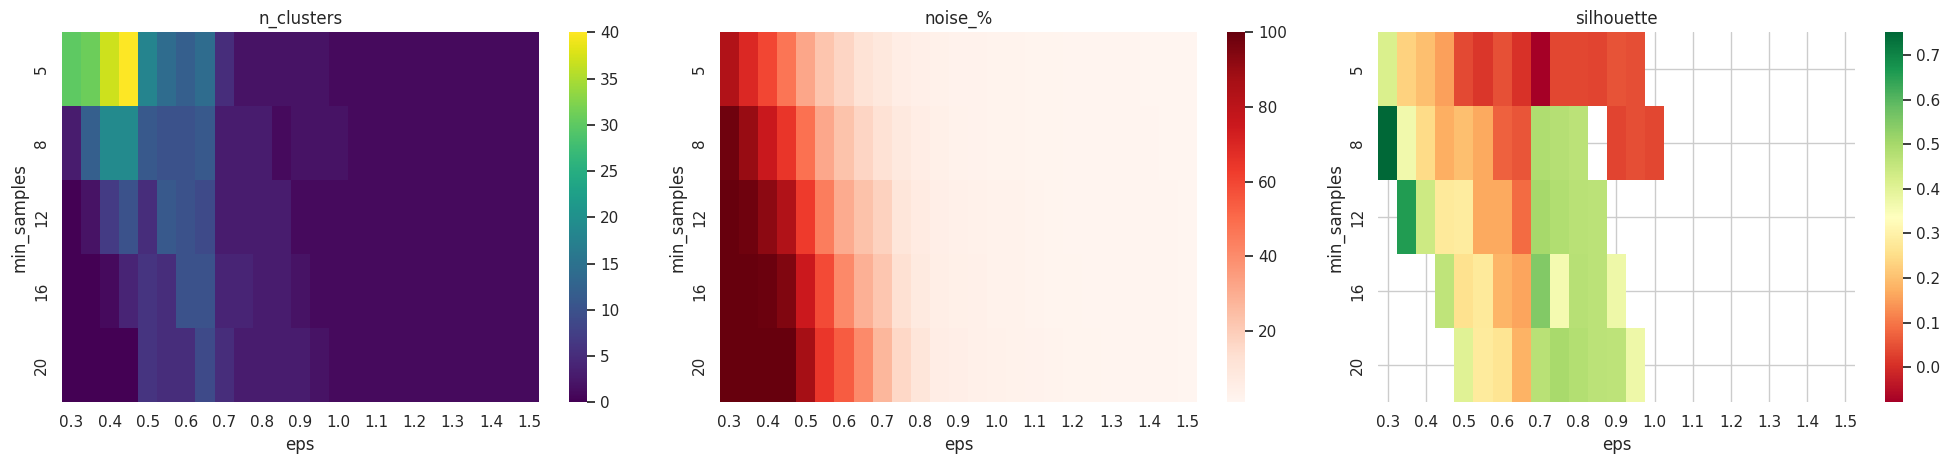

Top 5 settings by the selection rule:


,eps,min_samples,n_clusters,noise_%,silhouette,calinski_harabasz,davies_bouldin
42,0.70,12,3,18.0,0.500,1337.741,0.765
49,0.75,20,3,16.1,0.497,1334.093,0.770
41,0.70,8,3,12.3,0.488,1304.026,0.776
47,0.75,12,3,9.9,0.482,1301.147,0.786
54,0.80,20,3,10.0,0.480,1289.793,0.793


In [9]:
rows = []
for eps in np.round(np.arange(0.3, 1.55, 0.05), 2):
    for ms in [5, 8, 12, 16, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit(X).labels_
        rows.append({'eps': eps, 'min_samples': ms, **internal_metrics(X, lab)})
grid = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
for a, col, cmap in zip(ax, ['n_clusters', 'noise_%', 'silhouette'], ['viridis', 'Reds', 'RdYlGn']):
    sns.heatmap(grid.pivot(index='min_samples', columns='eps', values=col), annot=False, cmap=cmap, ax=a)
    a.set_title(col)
plt.tight_layout(); plt.show()

print('Top 5 settings by the selection rule:')
display(pick_best(grid).head(5).round(3))

### 6. Final DBSCAN model

In [10]:
best = pick_best(grid).iloc[0]
EPS, MIN_SAMPLES = float(best['eps']), int(best['min_samples'])     # change these two values to try others

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
labels = dbscan.labels_
core = np.zeros(len(X), dtype=bool); core[dbscan.core_sample_indices_] = True

print(f'eps = {EPS} | min_samples = {MIN_SAMPLES}')
print('Clusters      :', len(set(labels) - {-1}))
print('Core points   :', core.sum(), '| Border points:', ((~core) & (labels != -1)).sum(), '| Noise:', (labels == -1).sum())
print(pd.Series(labels).value_counts().sort_index().rename('employees').to_string())

eps = 0.7 | min_samples = 12
Clusters      : 3
Core points   : 879 | Border points: 350 | Noise: 269
-1    269
 0    634
 1    339
 2    256


### 7. Evaluation metrics
Noise points are not part of any cluster, so internal metrics are computed on the clustered points only. In the external check, noise (-1) counts as its own group.

In [11]:
metrics = internal_metrics(X, labels)
print('===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====')
print('Clusters found     :', metrics['n_clusters'], '| noise points:', metrics['noise_%'], '%')
print('Silhouette         :', round(metrics['silhouette'], 4), ' (higher is better)')
print('Calinski-Harabasz  :', round(metrics['calinski_harabasz'], 1), ' (higher is better)')
print('Davies-Bouldin     :', round(metrics['davies_bouldin'], 4), ' (lower is better)')

if HAS_TRUTH:
    ext = external_metrics(df['segment_true'], labels)
    print('\n===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====')
    for k_, v_ in ext.items():
        print(f'{k_:<13}: {v_:.4f}')

===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====
Clusters found     : 3 | noise points: 18.0 %
Silhouette         : 0.5002  (higher is better)
Calinski-Harabasz  : 1337.7  (higher is better)
Davies-Bouldin     : 0.7652  (lower is better)

===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====
ARI          : 0.5627
NMI          : 0.6522
homogeneity  : 0.6168
completeness : 0.6918
v_measure    : 0.6522


### 8. Visualization
Black **x** = noise (unusual employees that fit no dense group).

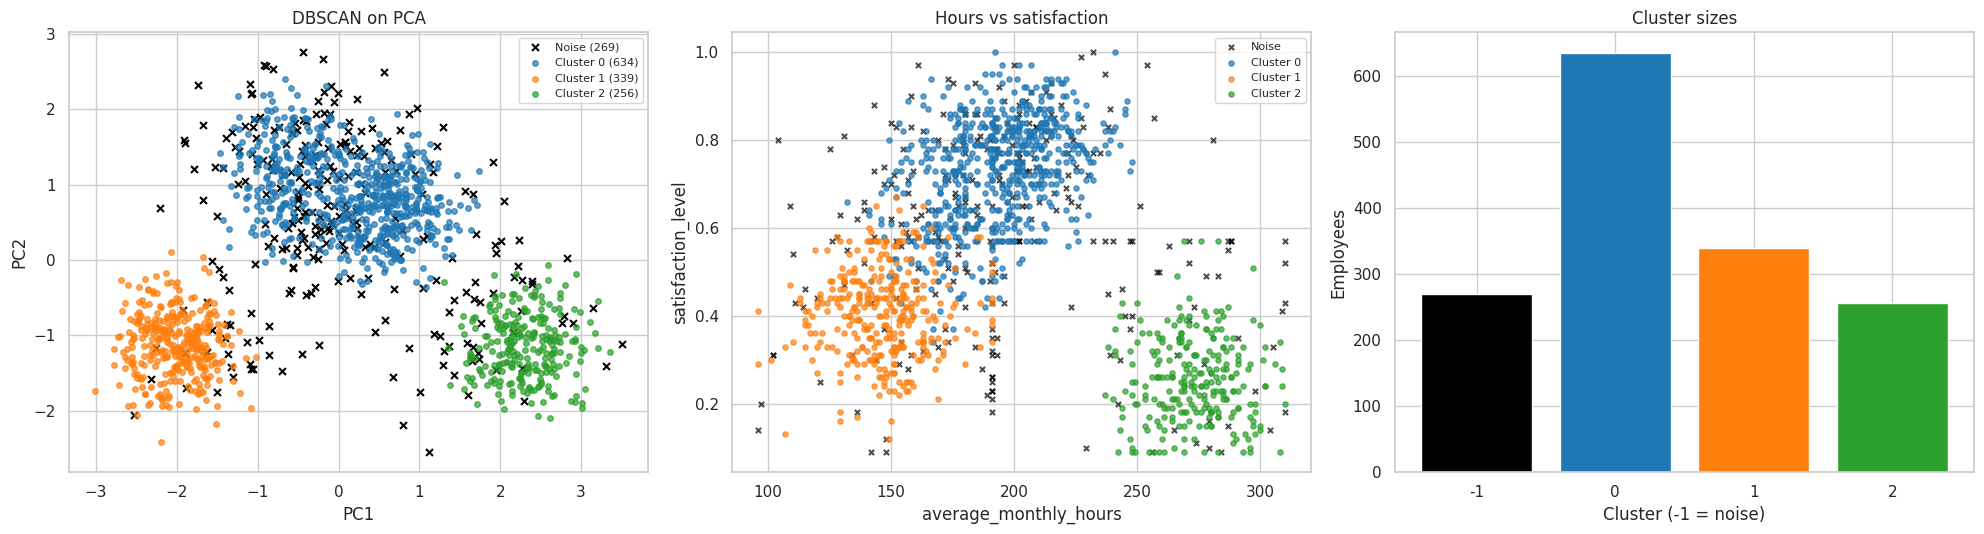

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
plot_clusters(Z, labels, ax[0], 'DBSCAN on PCA')

for c in sorted(set(labels)):
    m = labels == c
    ax[1].scatter(df.loc[m, 'average_monthly_hours'], df.loc[m, 'satisfaction_level'], s=14, alpha=0.7,
                  color='black' if c == -1 else sns.color_palette('tab10')[c % 10], marker='x' if c == -1 else 'o',
                  label='Noise' if c == -1 else f'Cluster {c}')
ax[1].set_xlabel('average_monthly_hours'); ax[1].set_ylabel('satisfaction_level'); ax[1].set_title('Hours vs satisfaction'); ax[1].legend(fontsize=8)

sizes = pd.Series(labels).value_counts().sort_index()
ax[2].bar(sizes.index.astype(str), sizes.values, color=['black' if i == -1 else sns.color_palette('tab10')[i % 10] for i in sizes.index])
ax[2].set_xlabel('Cluster (-1 = noise)'); ax[2].set_ylabel('Employees'); ax[2].set_title('Cluster sizes')
plt.tight_layout(); plt.show()

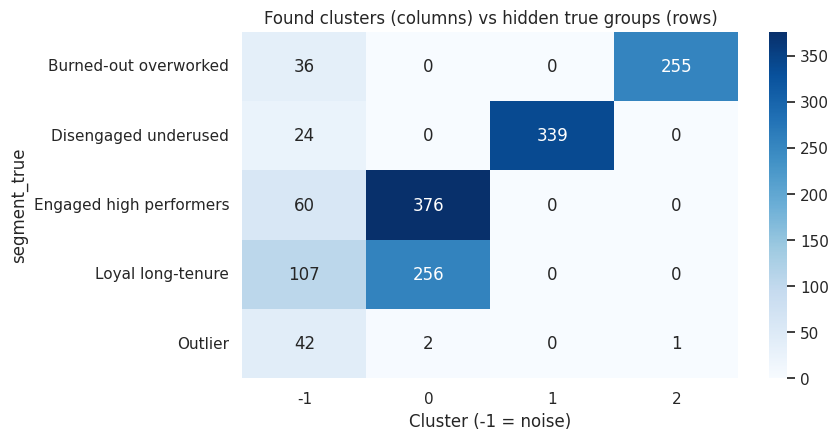

In [13]:
if HAS_TRUTH:
    plt.figure(figsize=(8, 4.5))
    sns.heatmap(pd.crosstab(df['segment_true'], labels), annot=True, fmt='d', cmap='Blues')
    plt.title('Found clusters (columns) vs hidden true groups (rows)'); plt.xlabel('Cluster (-1 = noise)'); plt.show()

**What to notice in this demo data (this run):**
- DBSCAN finds **3 clusters** (K-Means found 4). Two real groups, *Engaged high performers* and *Loyal long-tenure*, **touch each other** (no empty gap between them). A density-based method sees one connected dense area and puts them in the **same cluster**. Distance-based methods (K-Means, Ward) cut by distance, so they can still split them.
- DBSCAN is good at the **unusual employees**: 42 of the 45 real random outliers are labelled noise (-1). K-Means / Ward must put every outlier into some cluster.
- Many *Loyal long-tenure* employees (long tenure is an unusual value) also become noise, so **noise is not always "bad data"**: here it is partly a real group at the edge. Always look at who the noise employees are (table below).

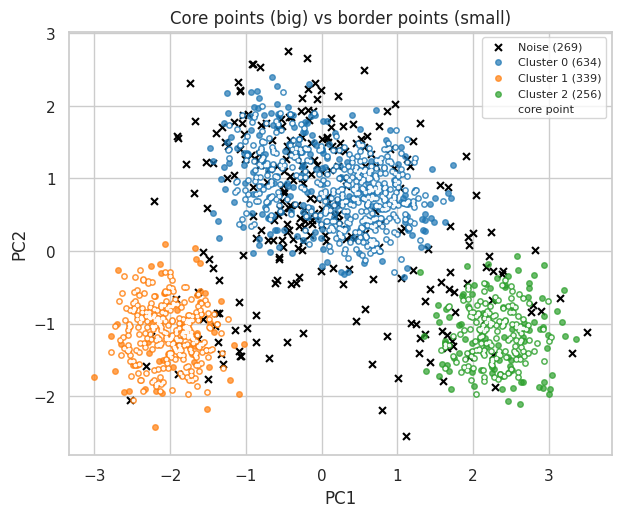

In [14]:
fig, ax = plt.subplots(figsize=(7, 5.5))
plot_clusters(Z, labels, ax, 'Core points (big) vs border points (small)')
ax.scatter(Z[core, 0], Z[core, 1], s=3, c='white', alpha=0.9, label='core point')
ax.legend(fontsize=8); plt.show()

### Cluster profile: who is in each cluster?
Green = high, red = low compared with the other clusters. Cluster -1 (if present) = noise / unusual employees.

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,size,share_%
cluster,,,,,,,,
-1,0.59,0.74,4.26,195.46,5.81,1.04,269,18.0
0,0.73,0.79,4.22,193.08,5.52,1.27,634,42.3
1,0.41,0.51,2.38,146.48,3.13,0.52,339,22.6
2,0.26,0.88,6.00,273.30,3.92,0.52,256,17.1


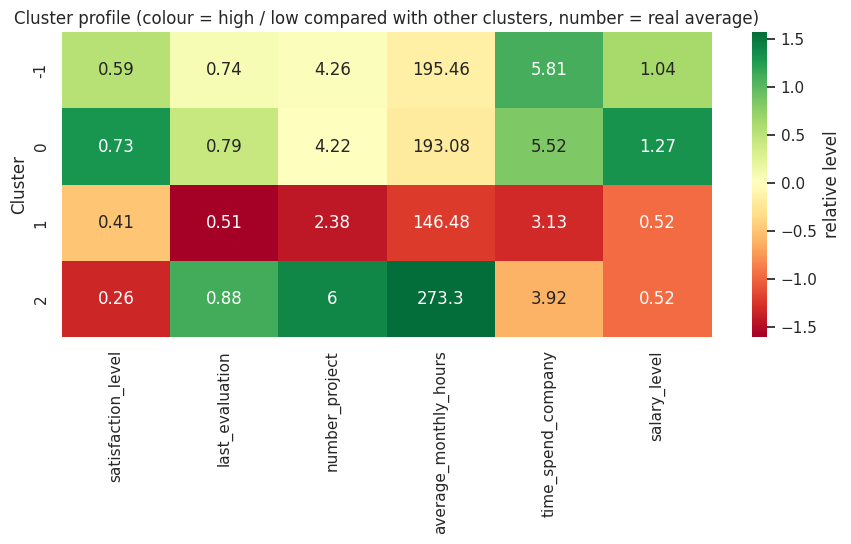

In [15]:
prof = cluster_profile(df, labels)
display(prof.round(2))
plot_profile(prof)

### 9. Who are the noise employees?
DBSCAN gives a list of employees that do not fit any group. For HR this is a useful 'special cases' list. We compare them with the clustered employees:

In [16]:
noise_df = df[labels == -1]
print('Noise employees:', len(noise_df))
display(pd.DataFrame({'noise (avg)': noise_df[FEATURES].mean(), 'clustered (avg)': df[labels != -1][FEATURES].mean(),
                      'noise (std)': noise_df[FEATURES].std(), 'clustered (std)': df[labels != -1][FEATURES].std()}).round(2))
if HAS_TRUTH:
    print('\nTrue group of the noise employees (how many of the real random outliers were found):')
    print(noise_df['segment_true'].value_counts().to_string())
    print('Real outliers in the data:', (df['segment_true'] == 'Outlier').sum())

Noise employees: 269


,noise (avg),clustered (avg),noise (std),clustered (std)
satisfaction_level,0.59,0.54,0.22,0.23
last_evaluation,0.74,0.73,0.15,0.16
number_project,4.26,4.08,1.50,1.44
average_monthly_hours,195.46,196.94,45.92,47.86
time_spend_company,5.81,4.53,2.65,2.08



True group of the noise employees (how many of the real random outliers were found):
segment_true
Loyal long-tenure          107
Engaged high performers     60
Outlier                     42
Burned-out overworked       36
Disengaged underused        24
Real outliers in the data: 45


### Assign new employees and save
This algorithm has no `predict` method for new data. A common solution: train a small **KNN classifier on the found cluster labels** and use it to place new employees in the nearest cluster.

In [17]:
mask = labels != -1
assigner = KNeighborsClassifier(n_neighbors=5).fit(X[mask], labels[mask])

new = pd.DataFrame({'satisfaction_level': [0.15, 0.85, 0.45], 'last_evaluation': [0.90, 0.88, 0.50],
                    'number_project': [7, 5, 2], 'average_monthly_hours': [280, 210, 140],
                    'time_spend_company': [4, 3, 3]})
new['cluster'] = assigner.predict(scaler.transform(new[FEATURES]))
display(new)

joblib.dump({'scaler': scaler, 'model': dbscan, 'assigner': assigner, 'features': FEATURES, 'profile': prof}, 'dbscan_hr_model.pkl')
df.assign(cluster=labels).to_csv('hr_dbscan_clusters.csv', index=False)
print('Saved: dbscan_hr_model.pkl, hr_dbscan_clusters.csv')

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,cluster
0,0.15,0.90,7,280,4,2
1,0.85,0.88,5,210,3,0
2,0.45,0.50,2,140,3,1


Saved: dbscan_hr_model.pkl, hr_dbscan_clusters.csv


### Download (Google Colab only)

In [18]:
try:
    from google.colab import files
    files.download('dbscan_hr_model.pkl'); files.download('hr_dbscan_clusters.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
